1. Instalasi library

In [1]:
import requests
import folium
import geopandas as gpd
from shapely.geometry import shape
from pyproj import CRS
import json
import os

2. Get Data Spasial from API MAPID

In [2]:
url = "https://geoserver.mapid.io/layers_new/get_layer?api_key=d96fcd98a91f4954ba5a51a8de2c3554&layer_id=6890de6d623dcfb726e90c33&project_id=67d241e182926d98678eea8b"
response = requests.get(url)
if response.status_code == 200:
 data = response.json()
 print("API Berhasil Diambil")
else:
 print("Gagal, status:", response.status_code)

API Berhasil Diambil


3. Visualisasi Data Spasial dari API MAPID yang awal

In [3]:
m = folium.Map(location=[-6.95, 107.68], zoom_start=12)
gj = folium.GeoJson(data, name="geojson").add_to(m)
m.fit_bounds(gj.get_bounds())

m

4. Buka sturktur data source dari API MAPID

In [4]:
features = data.get("features", [])
jumlah_baris = len(features)
jumlah_kolom = len(features[0].get("properties", {})) if features else 0
print ("jumlah baris (features):", jumlah_baris)
print ("jumlah kolom (properties):", jumlah_kolom)

if features:
    sample_props = features[0].get("properties", {})
    print("=== Struktur Kolom & Tipe Data ===")
    for key, value in sample_props.items():
        print(f"{key}: {type(value).__name__}")
else:
    print("Tidak ada fitur dalam data.")

jumlah baris (features): 151
jumlah kolom (properties): 6
=== Struktur Kolom & Tipe Data ===
fid: int
KABKOT: str
KECAMATAN: str
DESA: str
JUMLAH PENDUDUK: int
KELAS: str


5. Cek CRS data API

In [5]:
print("CRS:", data.get("crs"))
print("Jumlah Baris:", len(features))
print("Geometry type:", {f["geometry"]["type"] for f in features})
if features:
 print("Properties:", json.dumps(features[0]["properties"],
indent=2, ensure_ascii=False))
else:
 print("Tidak ada fitur")

CRS: None
Jumlah Baris: 151
Geometry type: {'MultiPolygon'}
Properties: {
  "fid": 69356,
  "KABKOT": "KOTA BANDUNG",
  "KECAMATAN": "BUAHBATU",
  "DESA": "SEKEJATI",
  "JUMLAH PENDUDUK": 26161,
  "KELAS": "TINGGI"
}


6.  Identifikasi CRS dari koordinat

In [6]:
if features:
    coords = features[0].get("geometry", {}).get("coordinates", [])

    if coords:
        # Ambil satu titik sampel (lon, lat)
        if isinstance(coords[0], list):
            # Polygon / MultiPolygon
            if isinstance(coords[0][0], list):
                sampel = coords[0][0][0][:2]   # MultiPolygon
            else:
                sampel = coords[0][:2]        # Polygon
        else:
            sampel = coords[:2]               # Point

        lon, lat = sampel

        if -180 <= lon <= 180 and -90 <= lat <= 90:
            crs = CRS.from_epsg(4326)
            print("CRS: EPSG:4326 (WGS84 / derajat)")
        else:
            crs = CRS.from_epsg(3857)
            print("CRS: EPSG:3857 (Projected / meter)")
    else:
        print("Koordinat tidak terbaca")
else:
    print("Tidak ada fitur pada data API")

CRS: EPSG:4326 (WGS84 / derajat)


7. Konversi ke GeoDataFrame & Manipulasi Data

In [7]:
gdf = gpd.GeoDataFrame.from_features(data.get("features", []))
print(gdf.head())

                                            geometry    fid        KABKOT  \
0  MULTIPOLYGON Z (((107.66286 -6.9463 0, 107.662...  69356  KOTA BANDUNG   
1  MULTIPOLYGON Z (((107.68846 -6.95045 0, 107.68...  69354  KOTA BANDUNG   
2  MULTIPOLYGON Z (((107.62167 -6.94278 0, 107.62...  69353  KOTA BANDUNG   
3  MULTIPOLYGON Z (((107.56871 -6.94956 0, 107.56...  69350  KOTA BANDUNG   
4  MULTIPOLYGON Z (((107.64517 -6.9475 0, 107.645...  69349  KOTA BANDUNG   

         KECAMATAN         DESA  JUMLAH PENDUDUK   KELAS  
0         BUAHBATU     SEKEJATI            26161  TINGGI  
1         GEDEBAGE  RANCABOLANG            12528  SEDANG  
2            REGOL    PASIRLUYU            17541  TINGGI  
3  BABAKAN CIPARAY    MARGASUKA            12755  SEDANG  
4         BUAHBATU    MARGASARI            42861  TINGGI  


8.  Filter Data Berdasarkan Atribut

In [8]:
gdf["KECAMATAN"] = gdf["KECAMATAN"].astype(str).str.upper()
filtered_gdf = gdf[gdf["KECAMATAN"] == "BUAHBATU"]
print(filtered_gdf.head())

                                              geometry    fid        KABKOT  \
0    MULTIPOLYGON Z (((107.66286 -6.9463 0, 107.662...  69356  KOTA BANDUNG   
4    MULTIPOLYGON Z (((107.64517 -6.9475 0, 107.645...  69349  KOTA BANDUNG   
14   MULTIPOLYGON Z (((107.64172 -6.94682 0, 107.64...  69316  KOTA BANDUNG   
111  MULTIPOLYGON Z (((107.66682 -6.93242 0, 107.66...  17550  KOTA BANDUNG   

    KECAMATAN       DESA  JUMLAH PENDUDUK   KELAS  
0    BUAHBATU   SEKEJATI            26161  TINGGI  
4    BUAHBATU  MARGASARI            42861  TINGGI  
14   BUAHBATU    CIJAURA            29607  TINGGI  
111  BUAHBATU  JATI SARI             9435  SEDANG  


9. Visualisasi Subset Data di Peta Interaktif

In [9]:
geojson = filtered_gdf.__geo_interface__
lat, lon = shape(filtered_gdf.geometry.iloc[0]).centroid.xy[::-1]
m = folium.Map([lat[0], lon[0]], zoom_start=13)
folium.GeoJson(
    geojson,
    tooltip=folium.GeoJsonTooltip(fields=["KECAMATAN", "DESA", "JUMLAH PENDUDUK", "KELAS"],
 aliases=["Kecamatan:", "Desa:",
"Penduduk:", "Kelas:"])
).add_to(m)
folium.LayerControl().add_to(m)
##m.save('map_output.html')

In [10]:
geojson = filtered_gdf.__geo_interface__
lat, lon = shape(filtered_gdf.geometry.iloc[0]).centroid.xy[::-1]
m = folium.Map([lat[0], lon[0]], zoom_start=13)
folium.GeoJson(
    geojson,
    tooltip=folium.GeoJsonTooltip(fields=["KECAMATAN", "DESA", "JUMLAH PENDUDUK", "KELAS"],
 aliases=["Kecamatan:", "Desa:",
"Penduduk:", "Kelas:"])
).add_to(m)
folium.LayerControl().add_to(m)
m

10. Simpan data di folder

In [11]:
out = "output.json"
os.makedirs(os.path.dirname(out) or ".", exist_ok=True)
with open(out, "w", encoding="utf-8") as f:
 json.dump(data, f, ensure_ascii=False, indent=2)
print("File tersimpan:", out)

File tersimpan: output.json


11.  Edit Polygon: Buffer, Simplify, dan Clip

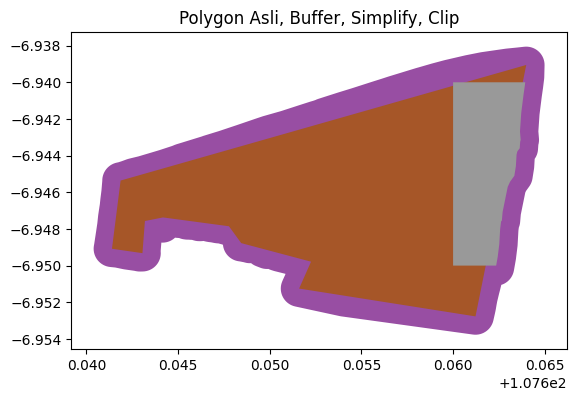

In [12]:
from shapely.geometry import Polygon
# Ambil satu polygon dari GeoDataFrame
poly = gdf.geometry.iloc[0]
# Buffer: menambah area 0.001 derajat
buffered_poly = poly.buffer(0.001)
# Simplify: mengurangi detail polygon
simplified_poly = poly.simplify(0.0005)
# Contoh clip/intersection (misal dengan bounding box)
bbox = Polygon([
 [107.66, -6.95], [107.68, -6.95], [107.68, -6.94], [107.66, -6.94]
])
clipped_poly = poly.intersection(bbox)
# Visualisasi hasil
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
gpd.GeoSeries([poly, buffered_poly, simplified_poly,
clipped_poly]).plot(ax=ax, cmap='Set1')
plt.title("Polygon Asli, Buffer, Simplify, Clip")
plt.show()

12. Edit Atribut Polygon di GeoDataFrame

In [13]:
# Ubah nilai KELAS menjadi kapital semua
gdf['KELAS'] = gdf['KELAS'].astype(str).str.upper()
# Tambah kolom baru: 'AREA_KM2' (luas polygon dalam km2)
gdf['AREA_KM2'] = gdf.geometry.area / 1e6
# Hapus kolom yang tidak diperlukan
gdf = gdf.drop(columns=['fid'])
print(gdf.head())

                                            geometry        KABKOT  \
0  MULTIPOLYGON Z (((107.66286 -6.9463 0, 107.662...  KOTA BANDUNG   
1  MULTIPOLYGON Z (((107.68846 -6.95045 0, 107.68...  KOTA BANDUNG   
2  MULTIPOLYGON Z (((107.62167 -6.94278 0, 107.62...  KOTA BANDUNG   
3  MULTIPOLYGON Z (((107.56871 -6.94956 0, 107.56...  KOTA BANDUNG   
4  MULTIPOLYGON Z (((107.64517 -6.9475 0, 107.645...  KOTA BANDUNG   

         KECAMATAN         DESA  JUMLAH PENDUDUK   KELAS      AREA_KM2  
0         BUAHBATU     SEKEJATI            26161  TINGGI  1.753849e-10  
1         GEDEBAGE  RANCABOLANG            12528  SEDANG  2.144991e-10  
2            REGOL    PASIRLUYU            17541  TINGGI  8.422721e-11  
3  BABAKAN CIPARAY    MARGASUKA            12755  SEDANG  9.649118e-11  
4         BUAHBATU    MARGASARI            42861  TINGGI  1.991328e-10  


13. Reproject Data ke CRS Lain

In [14]:
# Jika CRS belum ada, set dulu ke EPSG:4326 (WGS84)
if gdf.crs is None:
 gdf = gdf.set_crs(epsg=4326)
 print("CRS di-set ke EPSG:4326")
# Sekarang bisa reproject
gdf_proj = gdf.to_crs(epsg=3857)
print("CRS setelah reproject:", gdf_proj.crs)

CRS di-set ke EPSG:4326
CRS setelah reproject: EPSG:3857


14. Split Data Berdasarkan Atribut & Export per GeoJSON (Versi Benar)

In [15]:
for kelas, subset in gdf_proj.groupby('KELAS'):
   out_path = f"output_{kelas}.geojson"
   subset.to_file(out_path, driver='GeoJSON')
   print(f"File {kelas} tersimpan di {out_path}")

File RENDAH tersimpan di output_RENDAH.geojson
File SEDANG tersimpan di output_SEDANG.geojson
File TINGGI tersimpan di output_TINGGI.geojson


15. Merge Polygon

In [16]:
merged_poly = gdf_proj.unary_union
# Simpan hasil union ke GeoJSON
gdf_union = gpd.GeoDataFrame({'geometry': [merged_poly]},
crs=gdf_proj.crs)
union_path = "hasil_union.geojson"
gdf_union.to_file(union_path, driver='GeoJSON')
print("❌ File union polygon tersimpan di", union_path)

❌ File union polygon tersimpan di hasil_union.geojson


C:\Users\ASUS\AppData\Local\Temp\ipykernel_28268\2991444323.py:1: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  merged_poly = gdf_proj.unary_union


16. Dissolve berdasarkan attribut

In [17]:
gdf_dissolved = gdf_proj.dissolve(by='KABKOT')
dissolved_path = "hasil_dissolved.geojson"
gdf_dissolved.to_file(dissolved_path, driver='GeoJSON')
print("File dissolved per KABKOT tersimpan di", dissolved_path)

File dissolved per KABKOT tersimpan di hasil_dissolved.geojson


17. Cek dan edit CRS/Projection metadata

In [18]:
print("CRS saat ini:", gdf_proj.crs)
if gdf_proj.crs is None:
 gdf_proj = gdf_proj.set_crs(epsg=3857)
 print("CRS di-set ke EPSG:3857")

CRS saat ini: EPSG:3857


18. Export subet berdasarkan filter ke geoJSON

In [19]:
subset_buahbatu = gdf_proj[gdf_proj['KECAMATAN'] == 'BUAHBATU']
buahbatu_path = "buahbatu.geojson"
subset_buahbatu.to_file(buahbatu_path, driver='GeoJSON')
print("File Buahbatu tersimpan di", buahbatu_path)

File Buahbatu tersimpan di buahbatu.geojson


19. Export polygon hasil edit ke GeoJSON

In [20]:
# Buffer polygon pertama
buffered_poly = gdf_proj.geometry.iloc[0].buffer(100) # 100 meter (karena EPSG:3857)
gdf_buffered = gpd.GeoDataFrame({'geometry': [buffered_poly]},
crs=gdf_proj.crs)
buffered_path = "buffered.geojson"
gdf_buffered.to_file(buffered_path, driver='GeoJSON')
print("File buffered polygon tersimpan di", buffered_path)
# Simplify polygon pertama
simplified_poly = gdf_proj.geometry.iloc[0].simplify(50) # 50 meter tolerance
gdf_simplified = gpd.GeoDataFrame({'geometry': [simplified_poly]},
crs=gdf_proj.crs)
simplified_path = "simplified.geojson"
gdf_simplified.to_file(simplified_path, driver='GeoJSON')
print("❌ File simplified polygon tersimpan di", simplified_path)

File buffered polygon tersimpan di buffered.geojson
❌ File simplified polygon tersimpan di simplified.geojson


20. Cek validitas geometry

In [21]:
validity = gdf_proj.geometry.is_valid
print("Validitas geometry:", validity.value_counts())

Validitas geometry: True    151
Name: count, dtype: int64


21. Visualisasikan polygon after edit